# 06 — Case 3: Clustering Asteroid Orbits
**Inputs:** `data/processed/case3_orbits.parquet`, `reports/results/03_manifest.json`  
**Outputs:** `reports/results/06_*.csv`, `models/case3_kmeans.joblib`, `models/case3_dbscan.joblib`, figures.

## 1. Setup & data

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pda_utils as U

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

QUICK = False
SWEEP_N = 40_000 if QUICK else 200_000
DB_N    = 12_000 if QUICK else 60_000
SIL_N   = 8_000  if QUICK else 20_000
K_RANGE = range(2, 7) if QUICK else range(2, 13)
K_OVERRIDE = None                 # set an int to force k after you have looked at the sweep
rng = np.random.default_rng(U.SEED)

def savefig(name):
    plt.tight_layout(); plt.savefig(U.FIG / f"{name}.png", dpi=150); plt.show()

M = U.load_manifest(); FS = M["feature_sets"]
FEATS, FEATS_ANG = FS["case3_core"], FS["case3_with_angles"]
cols = ["full_name", "class", "neo", "pha", "a", "e", "i"] + FEATS_ANG
df = U.read_processed("case3", columns=cols)
print(df.shape, "| features:", FEATS)

scaler = StandardScaler().fit(df[FEATS])
X = scaler.transform(df[FEATS]).astype("float32")
sweep_idx = rng.choice(len(X), min(SWEEP_N, len(X)), replace=False)
Xs = X[sweep_idx]

(958520, 16) | features: ['a_tr', 'e_tr', 'i_tr']


## 2. K-Means: choosing k

In [2]:
rows = []
for k in K_RANGE:
    t0 = time.time()
    km = KMeans(n_clusters=k, n_init=3, random_state=U.SEED).fit(Xs)
    sub = rng.choice(len(Xs), min(SIL_N, len(Xs)), replace=False)
    rows.append(dict(k=k, inertia=km.inertia_,
                     silhouette=silhouette_score(Xs[sub], km.labels_[sub]),
                     davies_bouldin=davies_bouldin_score(Xs[sub], km.labels_[sub]),
                     min_cluster_share=np.bincount(km.labels_).min() / len(Xs)))
    print(f"k={k:2d}  silhouette={rows[-1]['silhouette']:.4f}  DB={rows[-1]['davies_bouldin']:.3f}  ({time.time()-t0:.0f}s)")
sweep = pd.DataFrame(rows).set_index("k"); sweep.to_csv(U.RES / "06_kmeans_sweep.csv")
sweep.round(4)

k= 2  silhouette=0.2865  DB=1.409  (7s)
k= 3  silhouette=0.2936  DB=1.019  (7s)
k= 4  silhouette=0.3105  DB=0.877  (7s)
k= 5  silhouette=0.2695  DB=1.006  (6s)
k= 6  silhouette=0.2331  DB=1.144  (6s)
k= 7  silhouette=0.2336  DB=1.128  (7s)
k= 8  silhouette=0.2694  DB=0.996  (7s)
k= 9  silhouette=0.2615  DB=1.002  (6s)
k=10  silhouette=0.2585  DB=0.981  (6s)
k=11  silhouette=0.2691  DB=0.957  (7s)
k=12  silhouette=0.2679  DB=1.017  (7s)


,inertia,silhouette,davies_bouldin,min_cluster_share
k,,,,
2,460762.5000,0.2865,1.4087,0.4748
3,360359.7500,0.2936,1.0194,0.0038
4,268035.6562,0.3105,0.8775,0.0038
5,234564.5312,0.2695,1.0055,0.0038
6,214683.2969,0.2331,1.1439,0.0038
7,196593.5625,0.2336,1.1278,0.0038
8,170826.5156,0.2694,0.9963,0.0038
9,156642.2812,0.2615,1.0018,0.0038
10,145098.7656,0.2585,0.9808,0.0038


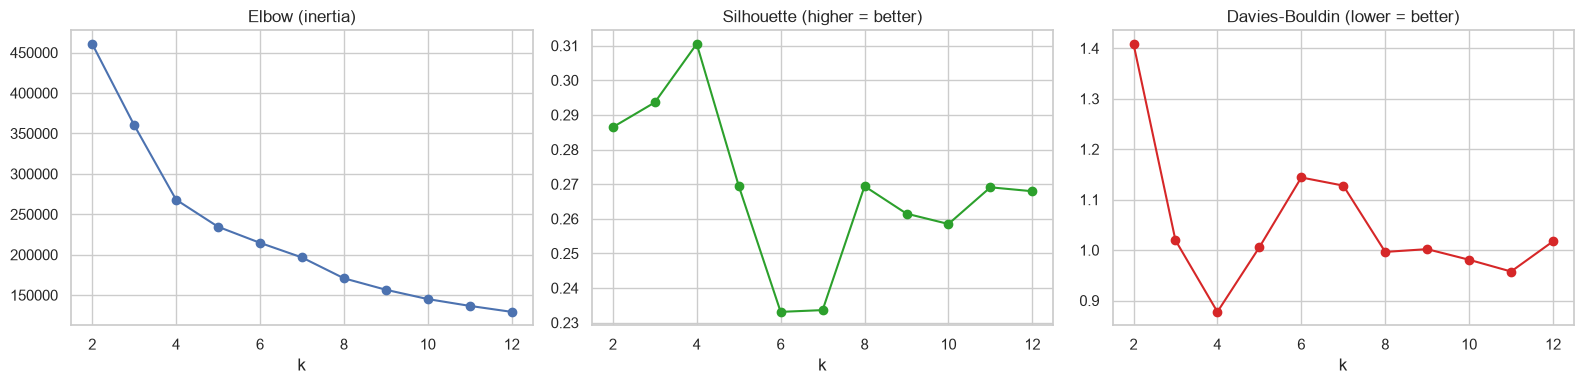

k chosen: 4 (max silhouette among k>=3)


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(sweep.index, sweep["inertia"], "o-"); axes[0].set_title("Elbow (inertia)")
axes[1].plot(sweep.index, sweep["silhouette"], "o-", color="tab:green"); axes[1].set_title("Silhouette (higher = better)")
axes[2].plot(sweep.index, sweep["davies_bouldin"], "o-", color="tab:red"); axes[2].set_title("Davies-Bouldin (lower = better)")
for a in axes: a.set_xlabel("k")
savefig("06_kmeans_k_selection")

cand = sweep.loc[sweep.index >= 3]           # k=2 only separates 'main belt' from 'the rest'
K_FINAL = int(K_OVERRIDE or cand["silhouette"].idxmax())
print("k chosen:", K_FINAL, "(max silhouette among k>=3)" if not K_OVERRIDE else "(manual override)")

## 3. K-Means: final model on all rows

In [4]:
km = KMeans(n_clusters=K_FINAL, n_init=5, random_state=U.SEED).fit(X)
df["km"] = km.labels_
sub = rng.choice(len(X), SIL_N, replace=False)
sil_km = silhouette_score(X[sub], km.labels_[sub])
print(f"K-Means k={K_FINAL}: silhouette={sil_km:.4f} (sample {SIL_N:,})")
print(df["km"].value_counts().sort_index().to_string())

K-Means k=4: silhouette=0.3095 (sample 20,000)
km
0    282651
1    379593
2      3777
3    292499


## 4. DBSCAN: eps from the k-distance graph, then a grid

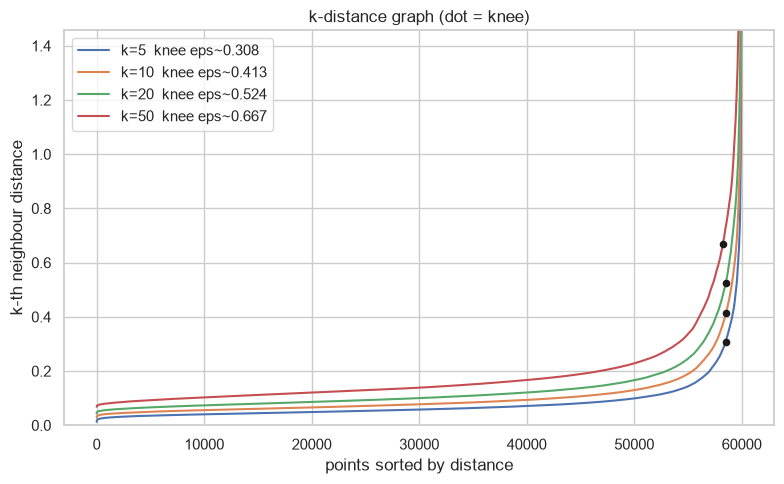

knee eps per min_samples: {5: 0.3079, 10: 0.4128, 20: 0.5237, 50: 0.6673}


In [5]:
idx_db = rng.choice(len(X), min(DB_N, len(X)), replace=False)
Xd = X[idx_db]; dfd = df.iloc[idx_db].reset_index(drop=True)

def knee(d):
    """Max distance below the chord of the (normalised) sorted k-distance curve."""
    x = np.linspace(0, 1, len(d)); y = (d - d.min()) / (d.max() - d.min() + 1e-12)
    return int(np.argmax(x - y))

MIN_SAMPLES = [5, 10, 20, 50]
fig, ax = plt.subplots(figsize=(8, 5)); knees = {}
for m in MIN_SAMPLES:
    dist, _ = NearestNeighbors(n_neighbors=m).fit(Xd).kneighbors(Xd)
    d = np.sort(dist[:, -1]); j = knee(d); knees[m] = float(d[j])
    ax.plot(d, label=f"k={m}  knee eps~{d[j]:.3f}"); ax.scatter([j], [d[j]], color="k", s=20, zorder=3)
ax.set_ylim(0, np.percentile(d, 99.5)); ax.set_xlabel("points sorted by distance"); ax.set_ylabel("k-th neighbour distance")
ax.set_title("k-distance graph (dot = knee)"); ax.legend()
savefig("06_dbscan_kdistance")
print("knee eps per min_samples:", {k: round(v, 4) for k, v in knees.items()})

In [6]:
rows = []
for m in MIN_SAMPLES:
    for mult in [0.5, 0.75, 1.0, 1.5, 2.0]:
        eps = knees[m] * mult
        t0 = time.time()
        lab = DBSCAN(eps=eps, min_samples=m, n_jobs=-1).fit_predict(Xd)
        nz = lab >= 0; ncl = len(set(lab[nz]))
        sil = np.nan
        if ncl >= 2:
            s = rng.choice(np.where(nz)[0], min(SIL_N, nz.sum()), replace=False)
            sil = silhouette_score(Xd[s], lab[s])
        big = (np.bincount(lab[nz]).max() / nz.sum()) if ncl else np.nan
        rows.append(dict(min_samples=m, eps=round(eps, 4), eps_x_knee=mult, n_clusters=ncl,
                         noise_pct=(~nz).mean() * 100, largest_cluster_share=big, silhouette_non_noise=sil))
grid = pd.DataFrame(rows); grid.to_csv(U.RES / "06_dbscan_grid.csv", index=False)
grid.round(4)

,min_samples,eps,eps_x_knee,n_clusters,noise_pct,largest_cluster_share,silhouette_non_noise
0,5,0.1540,0.50,63,5.7433,0.9558,-0.2224
1,5,0.2310,0.75,43,2.9833,0.9849,-0.1543
2,5,0.3079,1.00,31,1.7967,0.9854,0.1040
3,5,0.4619,1.50,9,0.6733,0.9902,0.4211
4,5,0.6159,2.00,7,0.2933,0.9895,0.4139
5,10,0.2064,0.50,13,5.3250,0.9597,0.0209
6,10,0.3096,0.75,3,2.8017,0.9890,0.2191
7,10,0.4128,1.00,7,1.5983,0.9915,0.3275
8,10,0.6192,1.50,4,0.5200,0.9904,0.4396
9,10,0.8256,2.00,2,0.2333,0.9975,0.8298


In [7]:
# A single giant blob gets a flattering silhouette, so we also cap the largest cluster's share.
ok = grid[(grid["n_clusters"] >= 3) & (grid["noise_pct"] <= 25) & (grid["largest_cluster_share"] <= 0.97)]
if not len(ok):
    print("No config satisfies largest_cluster_share <= 0.97; relaxing that constraint.")
    ok = grid[(grid["n_clusters"] >= 3) & (grid["noise_pct"] <= 25)]
pick = (ok if len(ok) else grid.dropna(subset=["silhouette_non_noise"])).sort_values("silhouette_non_noise", ascending=False).iloc[0]
print("DBSCAN choice (max silhouette with >=3 clusters, <=25% noise, largest cluster <=97%):"); print(pick.round(4).to_string())

db = DBSCAN(eps=float(pick["eps"]), min_samples=int(pick["min_samples"]), n_jobs=-1).fit(Xd)
dfd["db"] = db.labels_
nz = db.labels_ >= 0
s = rng.choice(np.where(nz)[0], min(SIL_N, nz.sum()), replace=False)
sil_db = silhouette_score(Xd[s], db.labels_[s]) if len(set(db.labels_[nz])) >= 2 else np.nan
print(f"\nclusters={len(set(db.labels_[nz]))}  noise={(~nz).mean()*100:.1f}%  silhouette(non-noise)={sil_db:.4f}")
print(dfd["db"].value_counts().sort_index().head(15).to_string())

DBSCAN choice (max silhouette with >=3 clusters, <=25% noise, largest cluster <=97%):
min_samples              20.0000
eps                       0.2618
eps_x_knee                0.5000
n_clusters                7.0000
noise_pct                 5.2300
largest_cluster_share     0.9698
silhouette_non_noise      0.1461

clusters=7  noise=5.2%  silhouette(non-noise)=0.1528
db
-1     3138
 0    55142
 1     1458
 2       85
 3       56
 4       60
 5       45
 6       16


## 5. Interpretation: what are these clusters?

In [8]:
def profile(frame, col):
    g = frame.groupby(col)
    out = pd.DataFrame({
        "n": g.size(), "share_%": g.size() / len(frame) * 100,
        "a_AU_median": g["a"].median(), "e_median": g["e"].median(), "i_deg_median": g["i"].median(),
        "top_class": g["class"].agg(lambda s: s.value_counts().index[0]),
        "top_class_%": g["class"].agg(lambda s: s.value_counts(normalize=True).iloc[0] * 100),
        "PHA_rate_%": g["pha"].agg(lambda s: (s == "Y").sum() / max(s.notna().sum(), 1) * 100),
        "NEO_rate_%": g["neo"].agg(lambda s: (s == "Y").mean() * 100),
    })
    return out.round(3)

prof_km = profile(df, "km"); prof_db = profile(dfd, "db")
prof_km.to_csv(U.RES / "06_kmeans_profile.csv"); prof_db.to_csv(U.RES / "06_dbscan_profile.csv")
print("K-Means clusters (all rows)"); display(prof_km)
print("DBSCAN clusters (sample; -1 = noise)"); display(prof_db)

K-Means clusters (all rows)


,n,share_%,a_AU_median,e_median,i_deg_median,top_class,top_class_%,PHA_rate_%,NEO_rate_%
km,,,,,,,,,
0,282651,29.488,2.816000,0.071,9.210,MBA,88.056,0.002,0.064
1,379593,39.602,2.426000,0.164,3.847,MBA,94.648,0.180,2.379
2,3777,0.394,43.765999,0.163,10.645,TNO,91.819,0.027,0.132
3,292499,30.516,2.693000,0.197,13.291,MBA,84.713,0.487,4.677


DBSCAN clusters (sample; -1 = noise)


,n,share_%,a_AU_median,e_median,i_deg_median,top_class,top_class_%,PHA_rate_%,NEO_rate_%
db,,,,,,,,,
-1,3138,5.230,2.415,0.260,9.461,APO,24.665,4.682,43.531
0,55142,91.903,2.657,0.145,7.138,MBA,96.290,0.000,0.005
1,1458,2.430,1.910,0.082,21.421,IMB,84.842,0.000,0.000
2,85,0.142,5.187,0.070,8.347,TJN,100.000,0.000,0.000
3,56,0.093,3.962,0.209,3.649,OMB,100.000,0.000,0.000
4,60,0.100,5.216,0.086,18.042,TJN,100.000,0.000,0.000
5,45,0.075,2.106,0.508,6.882,AMO,62.222,6.667,100.000
6,16,0.027,5.219,0.040,9.606,TJN,100.000,0.000,0.000


### 5.1 Do the clusters align with the existing `class` label?

In [9]:
def agreement(labels, classes, name):
    return dict(method=name, ARI=adjusted_rand_score(classes, labels), NMI=normalized_mutual_info_score(classes, labels))
agree = pd.DataFrame([agreement(df["km"], df["class"], "K-Means (all rows)"),
                      agreement(dfd["db"], dfd["class"], "DBSCAN (sample, noise = own label)")]).round(4)
cmp_tbl = pd.DataFrame({
    "method": ["K-Means", "DBSCAN"],
    "n_clusters": [K_FINAL, len(set(db.labels_[nz]))],
    "noise_%": [0.0, (~nz).mean() * 100],
    "silhouette": [sil_km, sil_db],
    "ARI_vs_class": agree["ARI"].values, "NMI_vs_class": agree["NMI"].values}).round(4)
cmp_tbl.to_csv(U.RES / "06_method_comparison.csv", index=False); cmp_tbl

,method,n_clusters,noise_%,silhouette,ARI_vs_class,NMI_vs_class
0,K-Means,4,0.00,0.3095,0.0213,0.0795
1,DBSCAN,7,5.23,0.1528,0.7223,0.5581


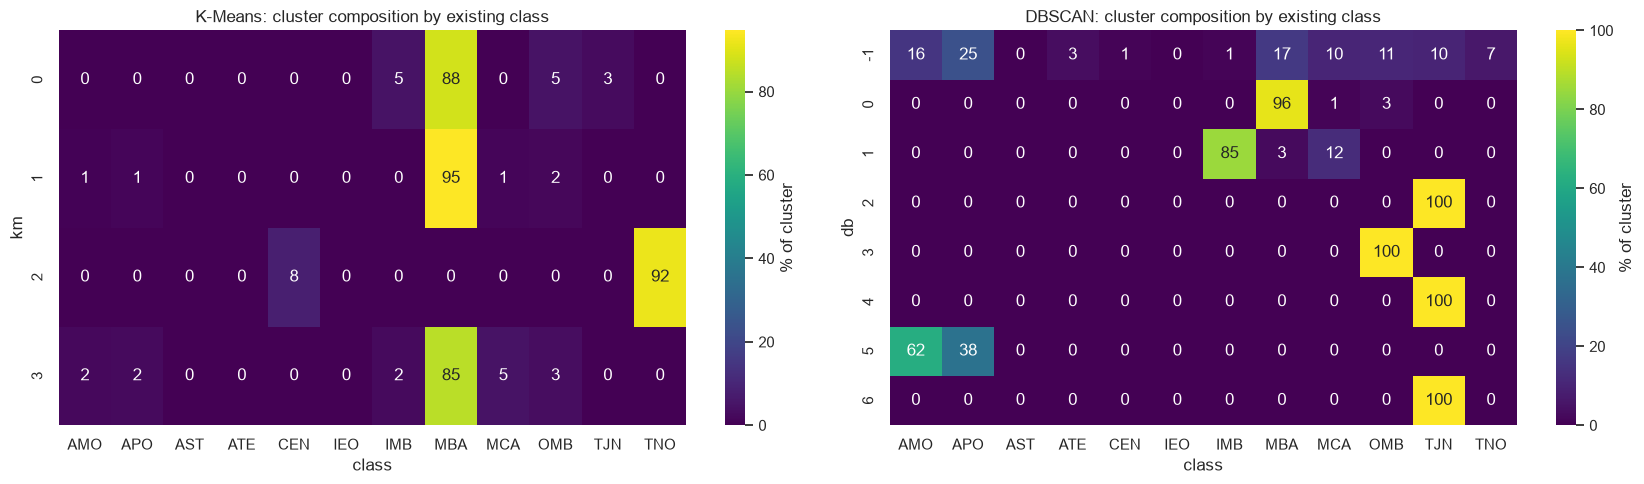

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, (frame, col, title) in zip(axes, [(df, "km", "K-Means"), (dfd, "db", "DBSCAN")]):
    ct = pd.crosstab(frame[col], frame["class"], normalize="index") * 100
    sns.heatmap(ct, annot=True, fmt=".0f", cmap="viridis", ax=ax, cbar_kws={"label": "% of cluster"})
    ax.set_title(f"{title}: cluster composition by existing class")
savefig("06_cluster_vs_class")

### 5.2 Orbital-space view

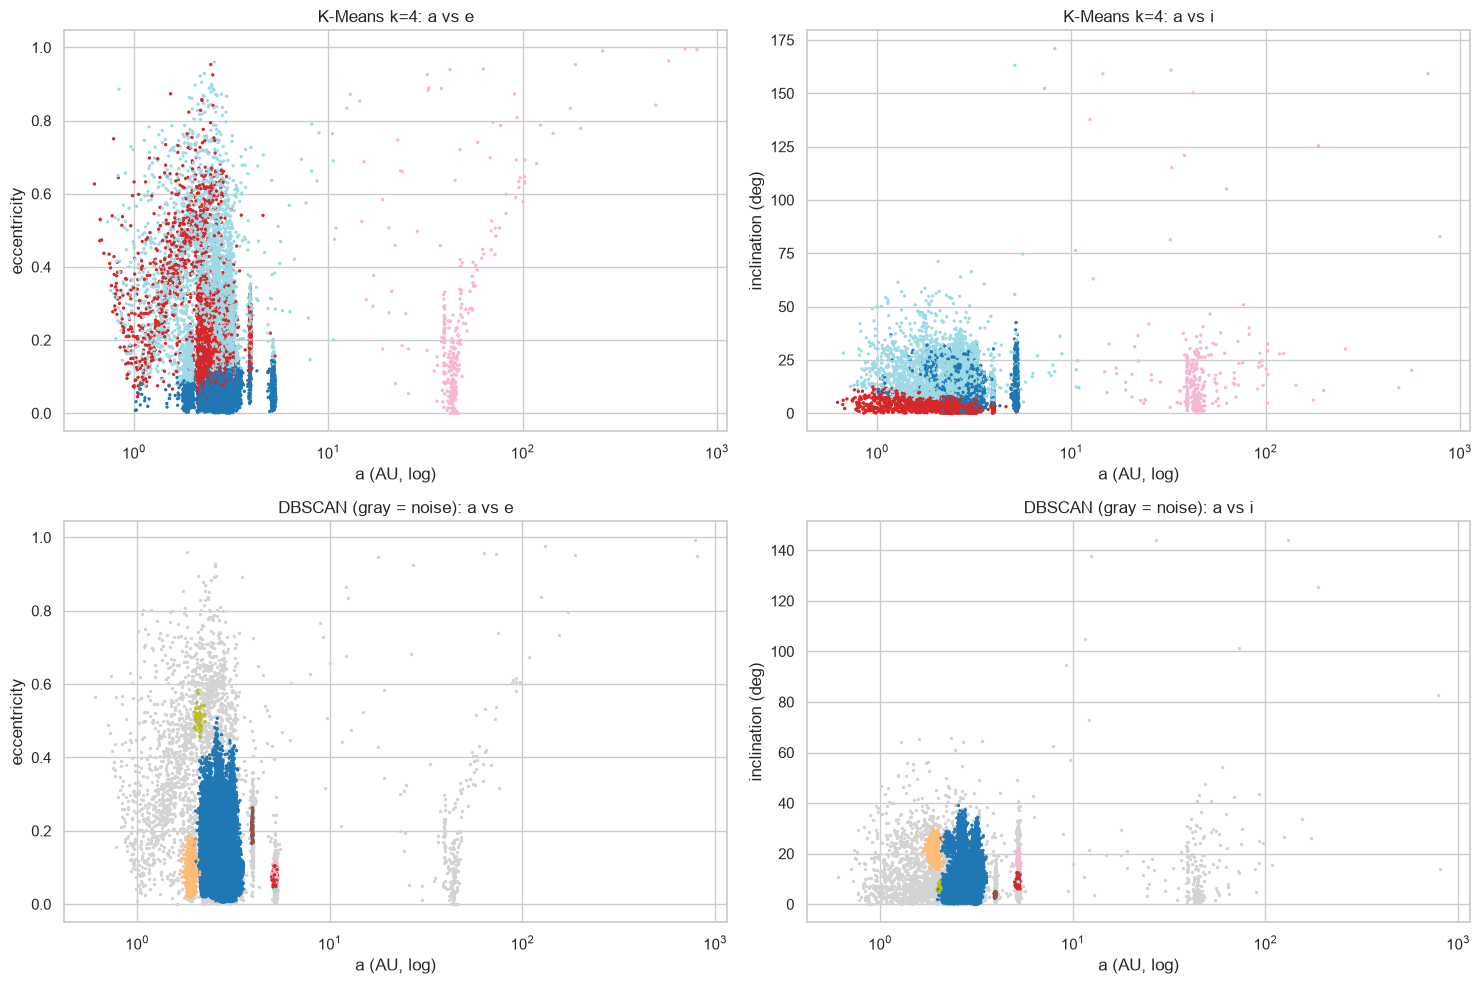

In [11]:
plot_n = 12_000 if QUICK else 80_000
pi = rng.choice(len(df), plot_n, replace=False); pf = df.iloc[pi]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for r_, (frame, col, title) in enumerate([(pf, "km", f"K-Means k={K_FINAL}"), (dfd, "db", "DBSCAN (gray = noise)")]):
    lab = frame[col].values; noise = lab < 0
    for c_, (yc, yl) in enumerate([("e", "eccentricity"), ("i", "inclination (deg)")]):
        ax = axes[r_, c_]
        ax.scatter(frame.loc[noise, "a"], frame.loc[noise, yc], s=2, c="lightgray")
        sc = ax.scatter(frame.loc[~noise, "a"], frame.loc[~noise, yc], s=2, c=lab[~noise], cmap="tab20")
        ax.set_xscale("log"); ax.set_xlabel("a (AU, log)"); ax.set_ylabel(yl); ax.set_title(f"{title}: a vs {yc}")
savefig("06_cluster_scatter")

### 5.3 Ablation: do the cyclic angles help?

In [12]:
sc2 = StandardScaler().fit(df[FEATS_ANG]); X2 = sc2.transform(df[FEATS_ANG].iloc[sweep_idx]).astype("float32")
km2 = KMeans(n_clusters=K_FINAL, n_init=3, random_state=U.SEED).fit(X2)
sub2 = rng.choice(len(X2), min(SIL_N, len(X2)), replace=False)
print(f"silhouette, a/e/i only        : {sil_km:.4f}")
print(f"silhouette, + sin/cos angles  : {silhouette_score(X2[sub2], km2.labels_[sub2]):.4f}")

silhouette, a/e/i only        : 0.3095
silhouette, + sin/cos angles  : 0.0968


## 6. Save models

In [13]:
joblib.dump({"scaler": scaler, "kmeans": km, "features": FEATS, "k": K_FINAL, "profile": prof_km},
            U.MODELS / "case3_kmeans.joblib")
core = db.core_sample_indices_
joblib.dump({"scaler": scaler, "features": FEATS, "eps": float(pick["eps"]), "min_samples": int(pick["min_samples"]),
             "core_X": Xd[core].astype("float32"), "core_labels": db.labels_[core], "profile": prof_db},
            U.MODELS / "case3_dbscan.joblib")
print("saved K-Means and DBSCAN bundles to", U.MODELS)

saved K-Means and DBSCAN bundles to C:\Projects\Planetary_Defense_Analytics\models
